<a href="https://colab.research.google.com/github/vinesh0830/statistics_and_trends/blob/main/Statistics_and_trends.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 11

In [4]:
# Run this cell in Google Colab:
import plotly.express as px
import pandas as pd

# 1. Load the global dataset (142 countries, 1952–2007)
df = px.data.gapminder()

# 2. Inspect the first 5 rows
print("Dataset successfully loaded! Shape:", df.shape)
display(df.head())

# 3. Optional: Save it as a CSV file in your Colab files
df.to_csv("world_development_data.csv", index=False)

Dataset successfully loaded! Shape: (1704, 8)


,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
0,Afghanistan,Asia,1952,28.801,8425333,779.445314,AFG,4
1,Afghanistan,Asia,1957,30.332,9240934,820.853030,AFG,4
2,Afghanistan,Asia,1962,31.997,10267083,853.100710,AFG,4
3,Afghanistan,Asia,1967,34.020,11537966,836.197138,AFG,4
4,Afghanistan,Asia,1972,36.088,13079460,739.981106,AFG,4


In [6]:
def clean_data(df: pd.DataFrame) -> pd.DataFrame:
    df_clean = df.copy()

    # Check & drop duplicates
    duplicates = df_clean.duplicated().sum()
    print(f"\nDuplicates found: {duplicates}")
    df_clean = df_clean.drop_duplicates()

    # Check for missing values
    missing = df_clean.isnull().sum()
    print("\nMissing values per column:\n", missing)
    # If missing values exist, fill or drop appropriately:
    df_clean = df_clean.dropna()

    # Feature Engineering / Transformation: Calculate total GDP
    df_clean['gdp'] = df_clean['gdpPercap'] * df_clean['pop']

    return df_clean

In [7]:
def compute_statistics(df: pd.DataFrame, column: str):
    """
    Computes key statistical metrics for a numeric series.
    """
    series = df[column]
    stats = {
        "Mean": series.mean(),
        "Median": series.median(),
        "Std Dev": series.std(),
        "Min": series.min(),
        "Max": series.max(),
        "Skewness": series.skew(),
        "Kurtosis": series.kurt()
    }
    return pd.DataFrame([stats], index=[column])

In [8]:
def plot_bar_chart(df: pd.DataFrame):
    """
    Plot 1: Horizontal Bar Chart showing average Life Expectancy by Continent (2007).
    """
    df_latest = df[df['year'] == 2007]
    avg_life_exp = df_latest.groupby('continent')['lifeExp'].mean().sort_values(ascending=True)

    fig, ax = plt.subplots(figsize=(8, 5))
    bars = ax.barh(avg_life_exp.index, avg_life_exp.values, color='#2b5c8f', edgecolor='black')

    # Add data labels
    for bar in bars:
        ax.text(bar.get_width() + 0.8, bar.get_y() + bar.get_height()/2,
                f"{bar.get_width():.1f} yrs", va='center', fontweight='bold', fontsize=10)

    ax.set_title("Figure 1: Mean Life Expectancy by Continent (2007)", fontsize=13, fontweight='bold', pad=12)
    ax.set_xlabel("Mean Life Expectancy (Years)", fontsize=11)
    ax.set_ylabel("Continent", fontsize=11)
    ax.set_xlim(0, 90)
    plt.tight_layout()
    plt.savefig("plot1_bar_chart.png", dpi=300)
    plt.show()

In [9]:
def plot_line_trend(df: pd.DataFrame):
    """
    Plot 2: Line graph tracking global and continental GDP per capita trends (1952-2007).
    """
    trend_data = df.groupby(['year', 'continent'])['gdpPercap'].mean().unstack()

    fig, ax = plt.subplots(figsize=(9, 5.5))
    for continent in trend_data.columns:
        ax.plot(trend_data.index, trend_data[continent], marker='o', linewidth=2, label=continent)

    ax.set_title("Figure 2: Historical Trends in GDP per Capita (1952 – 2007)", fontsize=13, fontweight='bold', pad=12)
    ax.set_xlabel("Year", fontsize=11)
    ax.set_ylabel("Average GDP per Capita (USD $)", fontsize=11)
    ax.legend(title="Continent", loc="upper left", frameon=True)
    plt.tight_layout()
    plt.savefig("plot2_line_trend.png", dpi=300)
    plt.show()

In [10]:
def plot_heatmap(df: pd.DataFrame):
    """
    Plot 3: Correlation Heatmap examining relationships among continuous variables.
    """
    numeric_df = df[['lifeExp', 'pop', 'gdpPercap', 'gdp']].corr()

    fig, ax = plt.subplots(figsize=(7, 5.5))
    sns.heatmap(numeric_df, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
                linewidths=1, square=True, cbar_kws={"shrink": .8}, ax=ax)

    ax.set_title("Figure 3: Pearson Correlation Heatmap of Socioeconomic Indicators",
                 fontsize=13, fontweight='bold', pad=12)
    plt.tight_layout()
    plt.savefig("plot3_correlation_heatmap.png", dpi=300)
    plt.show()


Duplicates found: 0

Missing values per column:
 country      0
continent    0
year         0
lifeExp      0
pop          0
gdpPercap    0
iso_alpha    0
iso_num      0
dtype: int64

--- Summary Statistics (Life Expectancy) ---
              Mean   Median    Std Dev     Min     Max  Skewness  Kurtosis
lifeExp  59.474439  60.7125  12.917107  23.599  82.603 -0.252702 -1.126685

--- Summary Statistics (GDP Per Capita) ---
                  Mean       Median      Std Dev         Min          Max  \
gdpPercap  7215.327081  3531.846989  9857.454543  241.165876  113523.1329   

           Skewness   Kurtosis  
gdpPercap  3.850272  27.515894  


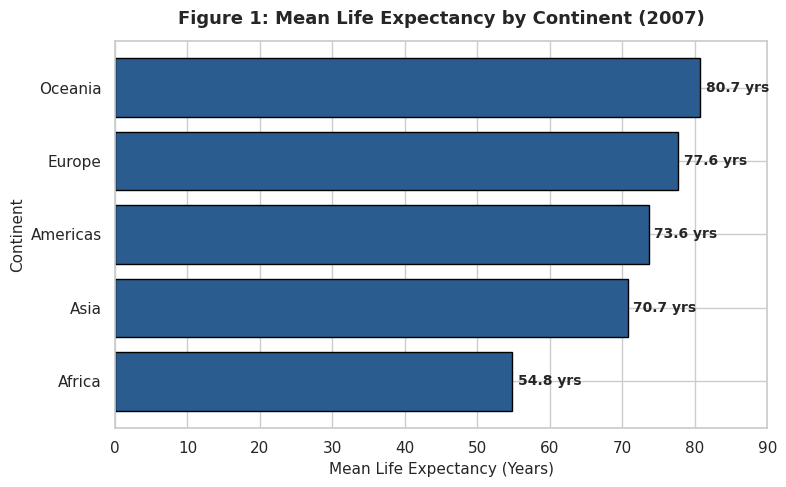

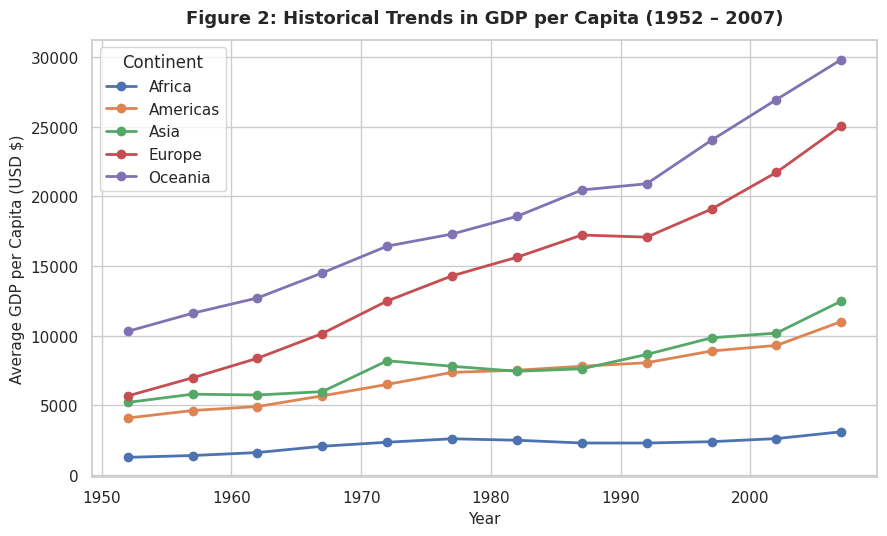

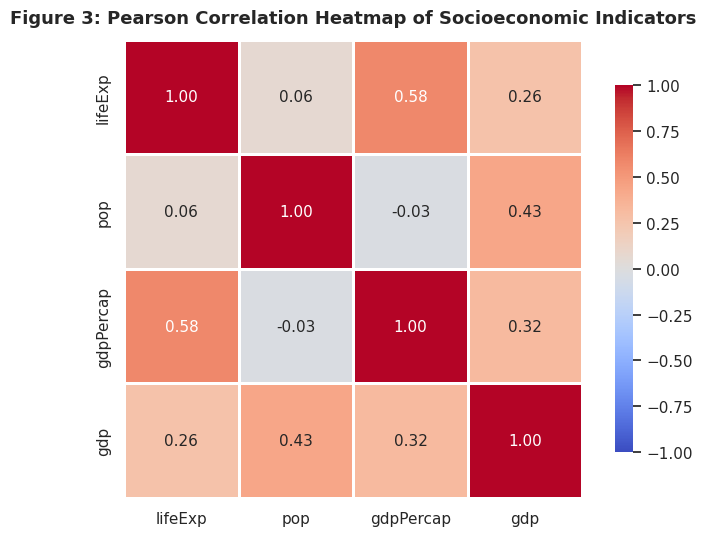

In [12]:
raw_df = df
df_cleaned = clean_data(raw_df)
print("\n--- Summary Statistics (Life Expectancy) ---")
print(compute_statistics(df_cleaned, 'lifeExp'))
print("\n--- Summary Statistics (GDP Per Capita) ---")
print(compute_statistics(df_cleaned, 'gdpPercap'))
# Generate and save all 3 figures
plot_bar_chart(df_cleaned)
plot_line_trend(df_cleaned)
plot_heatmap(df_cleaned)